# 第 18 步：真实 A 股快照核对与教学回放

<!-- SNAPSHOT_NOTE -->

## 数据准备说明

本页记录完整快照上的实际运行。通过 GitHub 克隆源码后，先在仓库根目录运行 `python publication/restore_snapshot.py`，恢复同版本的 `data/` 与 `runs/`，再执行本步。[完整数据与大型结果索引](../../publication/ASSET_INDEX.md)保留全部路径和哈希；本页图表与 Notebook 已保存输出可直接阅读。

## 目标：接入真实行情前先核对数据含义

前面的步骤已经用人工数据检验数据、因子、成交与账户链条。本步读取已保存的真实历史快照，逐只核对原价、后复权价格、成交量与换手率单位，检查独立交易日历、固定股票池的缺口和可成交状态，再运行同一研究流水线。

“价格是真实历史观察”不等于“历史订单一定能成交”。当前数据是 30 只手工固定股票的教学池，不是历史全 A 股，也不是可追溯的指数动态成分。成交状态全部未知，回放依赖显式的教学假设。这个限定影响结果解释，需要同时写入图题、方法和账户入口。

## 输入来源、版本与运行命令

数据沿用 [metadata.json](../../data/market_teaching/metadata.json) 记录的来源：AKShare `stock_zh_a_hist` 对接的东方财富历史日线，以及 `tool_trade_date_hist_sina` 保存的交易日历。快照取数版本为 AKShare `1.20.22`，取数时间记录为 `2026-11-02T11:58:38.200292+00:00`。这些是快照的来源记录，不意味着将来版本仍会返回完全相同的数据。

在仓库根目录执行：

```powershell
.\.venv\Scripts\python.exe -m ashare_lab check-data --data data/market_teaching
.\.venv\Scripts\python.exe examples/18_real_market_data.py
```

本步读取现成 CSV，不联网重新下载，也不需要安装 AKShare。环境仍只需此前固定的 NumPy、pandas、Matplotlib 与本项目。直接调用研究入口时，在命令中明确成交假设，并选用新输出目录保留旧实验：

```powershell
.\.venv\Scripts\python.exe -m ashare_lab run --data data/market_teaching --config configs/market_teaching.json --out runs/my_market_replay --allow-unknown-status
```

未指定 `--allow-unknown-status` 时，命令行会在回测前拒绝未知状态。加上它只是接受当前教学假设，不会把源表里的 `status_known=False` 改成 `True`。

前置配置是 [market_teaching.json](../../configs/market_teaching.json)，正式研究期为 2023—2025 年，按年划分开发、验证、测试。更早的 2019—2022 年观察仍用于滚动预热。课内输出在 `runs/lesson18_real_market/`，完整七策略实验在其 `experiment/` 子目录。

![真实行情教学回放图](../../runs/lesson18_real_market/real_market_nav_drawdown.png)

图中标明“后复权价格小数单位、成交状态未核实、固定教学费用”。它不是券商成交记录，也不是已验证的实盘曲线。横轴年度分界即使落在元旦，也只是时间刻度，不表示当日一定开市。

## 用哈希核对快照身份

每只股票保留原始与后复权响应各一份，加上日历来源，共 61 个原文件。`verify_source_files` 将文件当前 SHA-256 与 `metadata` 记录逐一比较：

```python
actual = sha256(data_dir / "raw" / name)
if actual != expected:
    raise ValueError("原始快照哈希不一致")
```

第一行计算文件内容标识，第二行阻止不同快照被无声混入。哈希一致只证明本地文件与已保存记录相同，不能证明供应商数据没有错误。标准化四个输入文件的哈希也会记录，并在整条流水线运行后再次比较，确认本次实验没有修改原始观察。

[source_hash_checks.csv](../../runs/lesson18_real_market/source_hash_checks.csv) 显示 61 个文件均匹配。文件名相同不足以证明来源一致；保留原始响应，也有助于追查清洗后结果的来源。

## 逐字段核对价格与单位

规范化表保留原始 `open/high/low/close`，另用 `adj_open/adj_close` 保存供应商 `hfq` 后复权价。代码先让原价、复权价、标准化表的日期索引一一匹配，再比较数值：

```python
expected["adj_open"] = adjusted["开盘"]
expected["adj_close"] = adjusted["收盘"]
expected["volume"] = raw["成交量"] * 100
expected["turnover"] = raw["换手率"] / 100
```

前两行明确收益研究的价格来源；第三行把“手”转为“股”；第四行把百分数换手率转为小数比例。代码 `000001` 必须以六位字符串保存，不能读成整数 1。原价与复权价不能混用计算同一收益区间，否则企业行动引起的尺度变化可能被误当作可交易收益。

[normalization_checks.csv](../../runs/lesson18_real_market/normalization_checks.csv) 覆盖 30 只股票。价格与成交量最大误差均为 0，换手率最大误差约 (9.98\times10^{-17})，属于浮点表达误差。对齐失败或字段明显不一致时应停止，不能用 `fillna` 把表凑齐。

## 区分 43 条完整网格缺口与 37 条 eligible 缺口

全快照有 1699 个市场交易日、30 只固定股票。完整笛卡尔网格应有 (1699\times30=50970) 行，实际价格有 50927 行，少 43 行。现有 `universe` 按每只股票“首个可见行情日”开始标为 eligible，因此其中 6 行没有计入合格池缺口，剩下 37 行才是当前定义下的 eligible 缺口。

这两个数字都需要保存，不能把 37 说成整个固定网格的全部缺口。额外 6 行是 `600030` 在 2019 年 1 月 2、3、4、7、8、9 日；首条观察之前没有数据，也不能据此认定股票尚未上市。上市、IPO 排除与历史资格需要独立证据，当前适配器没有提供。

合格缺口按年为 2019 年 20 行、2021 年 10 行、2022 年 7 行，涉及 `000333/000651/002415/600009/600030`。[missing_fixed_pool_rows.csv](../../runs/lesson18_real_market/missing_fixed_pool_rows.csv) 和 [yearly_coverage.csv](../../runs/lesson18_real_market/yearly_coverage.csv) 保留了具体缺失日期，便于逐行检查。

2023—2025 年共有 727 个来源日历交易日，固定 30 股应有 21810 行，实际也有 21810 行，该段行情缺口为零。覆盖检查在研究区间发现缺行就会停止，不把“没有观察”自动解释成休市或零收益。

## 保留完整真实区间的失败证据

原本按 2020—2025 年运行时，引擎在持有 `600009` 的 2021-06-10 找不到价格行，报出 `Missing held price row`，记录保存在 [failed_2020_2025.json](../../runs/failed_2020_2025.json)。原响应中 2021-06-09 之后的下一条记录为 2021-06-25；这支持“观察存在缺口”，但不足以证明停牌原因与应采用的估值规则已经核实。

这只股票没有被删除，也没有用未来复牌价回填，缺口仍按缺失处理，不作为市场休市。项目记录把正式教学段按覆盖检查冻结为 2023—2025 年，并在更早历史中保留缺口；滚动窗口遇到缺日会无效，不会自动缩成较少观察。

这个范围选择使有限教学回放可以运行，不意味着 2020—2025 年完整真实实证已经完成，也不意味着区间内成交状态已被核实。当前所有年份结果已经可见，本步是已有快照的复现，不是新的未见测试实验。

## 保留未知状态，显式采用教学成交假设

当前快照全部 50927 行 `status_known=False`，所有已观察行成交量大于零，适配器因此将 `can_buy/can_sell` 设为真。研究段 21810 行也全部未知。规范化核对会明确拒绝把这些状态改成已知：

```python
if normalized["status_known"].any():
    raise ValueError("这份快照的成交状态应保持未知")
results, research, metric_table = run_pipeline(
    data_dir, config_path, output_dir / "experiment", allow_unknown_status=True,
)
```

前三行保护源数据语义，后面显式选择教学假设。允许未知状态不会解除缺失持仓价格的硬错误，日线成交量也不能证明开盘盘口能容纳订单。历史 ST、退市、停复牌、板块涨跌停及开盘可成交状态都仍需补充；当前 0 拒单来自标记假设，不代表流动性已经验证。

## 真实行情教学结果

以下数字来自 [strategy_benchmark_metrics.csv](../../runs/lesson18_real_market/strategy_benchmark_metrics.csv)，同为一倍教学费率：

| 结果 | 三因子策略 | 同池等权基准 |
| --- | ---: | ---: |
| 正式账户日数 | 727 | 727 |
| 累计收益 | 27.0063% | 19.7282% |
| 252 日口径复合年化 | 8.6398% | 6.4401% |
| 年化波动 | 11.7409% | 12.3023% |
| 最大回撤幅度 | 14.1726% | 13.5898% |
| 期末权益 | 1270062.7651 | 1197282.2620 |
| 累计经济成本 | 47889.0106 | 2129.0505 |
| 成交笔数 | 549 | 1050 |

策略终值比基准多约 6.0788%，累计收益差为 7.2781 个百分点。2025 年策略累计约 3.3587%，基准约 8.0429%，策略在该年相对落后约 4.3355%。解读时，我不会只摘取全段相对领先而省略这一年。

两个账户从 2023-01-03 的现金净值 1 开始，首次买入为 2023-02-01，最后执行为 2025-12-01，最后一天仍分别有 10 只和 30 只股票。本引擎用后复权价格小数单位表达经济收益，不另行建立企业行动现金流与原始股数账，也没有整手、最低佣金、容量冲击和历年税费表。真实数据并没有自动使这些教学简化消失。

## 验收、结论与交付入口

[accounting_audit.csv](../../runs/lesson18_real_market/accounting_audit.csv) 核对七条策略路径：每日现金加持仓等于权益、收益连乘等于净值、费用合计对应逐笔成交、所有成交晚于信号。最大权益恒等式误差约 (2.33\times10^{-10}) 元，不影响经济解释。[完整研究报告](../../runs/lesson18_real_market/experiment/report.html)、[数据质量](../../runs/lesson18_real_market/data_quality.json)和[方法边界](../../runs/lesson18_real_market/methodology.json)也一并保留，使收益图可以回到具体数据与假设。

本步表明，同一工程已经接入这份真实固定股票池快照，并能在明确假设下复现。固定幸存者与选择偏差、未知历史成交条件和不完整企业行动账仍限制研究外推。下一步整理代码、课程、数据、失败记录、测试和结果，使“可以重新运行”和“哪些尚未完成”都能检查。

[完整脚本](../../examples/18_real_market_data.py) · [下一步：复现验收与交付](../19_finalize_project/README.md)

## 完整可运行实现

上面的片段用于解释思路；下面各单元按顺序执行完整脚本。先定位仓库根目录，并显式设置脚本路径，使 `__file__` 在 Notebook 中也有明确含义。

In [1]:
from pathlib import Path
import os
import sys

PROJECT_ROOT = next((candidate for candidate in [Path.cwd(), *Path.cwd().parents]
                     if (candidate / "pyproject.toml").exists()
                     and (candidate / "examples/01_read_prices.py").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("我需要从本项目目录或它的子目录打开 Notebook。")
sys.path.insert(0, str(PROJECT_ROOT / "src"))
os.chdir(PROJECT_ROOT)
__file__ = str(PROJECT_ROOT / 'examples/18_real_market_data.py')
sys.argv = [__file__]


### 完整实现 · 单元 1

In [2]:
r"""第十八课：真实 A 股快照接入、数据核对与教学成交回放。

运行：.\.venv\Scripts\python.exe examples/18_real_market_data.py
复现已保存的真实历史快照；行情完整不等于历史成交状态已经核实。
"""

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import PercentFormatter

from ashare_lab.cli import run_pipeline
from ashare_lab.config import load_config
from ashare_lab.data import data_quality, load_dataset, sha256, write_json

### 完整实现 · 单元 2

In [3]:
def verify_source_files(data_dir, metadata):
    """原始响应哈希匹配只证明快照未变，不证明供应商数据绝对正确。"""
    rows = []
    for name, expected in metadata["source_files"].items():
        actual = sha256(data_dir / "raw" / name)
        rows.append(dict(file=name, expected_sha256=expected, actual_sha256=actual, matches=actual == expected))
    checks = pd.DataFrame(rows)
    if checks.empty or not checks["matches"].all():
        raise ValueError("原始响应与 metadata 中保存的哈希不一致，停止复现。")
    return checks

### 完整实现 · 单元 3

In [4]:
def verify_normalization(data_dir, prices, metadata):
    """逐只复核原价、后复权价及单位转换，保留六位字符串代码。"""
    checks = []
    for symbol in metadata["symbols"]:
        raw = pd.read_csv(data_dir / "raw" / f"{symbol}_raw.csv",
                          dtype={"股票代码": str}, parse_dates=["日期"]).set_index("日期").sort_index()
        adjusted = pd.read_csv(data_dir / "raw" / f"{symbol}_hfq.csv",
                               dtype={"股票代码": str}, parse_dates=["日期"]).set_index("日期").sort_index()
        normalized = prices.loc[prices["symbol"].eq(symbol)].set_index("date").sort_index()
        pd.testing.assert_index_equal(raw.index, adjusted.index, check_names=False)
        pd.testing.assert_index_equal(raw.index, normalized.index, check_names=False)

        expected = pd.DataFrame(index=raw.index)
        for english, chinese in [("open", "开盘"), ("high", "最高"), ("low", "最低"), ("close", "收盘")]:
            expected[english] = raw[chinese]
        expected["adj_open"] = adjusted["开盘"]
        expected["adj_close"] = adjusted["收盘"]
        expected["volume"] = raw["成交量"] * 100
        expected["turnover"] = raw["换手率"] / 100
        np.testing.assert_allclose(normalized[expected.columns], expected, rtol=0, atol=1e-8)
        np.testing.assert_array_equal(normalized["can_buy"], normalized["volume"] > 0)
        np.testing.assert_array_equal(normalized["can_sell"], normalized["volume"] > 0)
        if normalized["status_known"].any():
            raise ValueError("这份快照的成交状态应保持未知；不能伪装成已核实。")
        errors = (normalized[expected.columns] - expected).abs().max()
        checks.append(dict(symbol=symbol, rows=len(normalized), raw_adjusted_dates_match=True,
                           max_price_error=float(errors[["open", "high", "low", "close", "adj_open", "adj_close"]].max()),
                           max_volume_error=float(errors["volume"]), max_turnover_error=float(errors["turnover"])))
    return pd.DataFrame(checks)

### 完整实现 · 单元 4

In [5]:
def inspect_coverage(prices, universe, calendar, metadata, config):
    """同时报告全笛卡尔缺口与当前 eligible 定义下的缺口。"""
    full_grid = pd.MultiIndex.from_product([calendar, metadata["symbols"]],
                                            names=["date", "symbol"]).to_frame(index=False)
    coverage = full_grid.merge(universe, on=["date", "symbol"], how="left", validate="one_to_one")
    if coverage["eligible"].isna().any():
        raise ValueError("股票池定义缺少日期/股票记录，不能默认为合格。")
    coverage = coverage.merge(prices[["date", "symbol"]], on=["date", "symbol"],
                               how="left", validate="one_to_one", indicator=True)
    coverage["missing"] = coverage["_merge"].eq("left_only")
    coverage["missing_eligible"] = coverage["missing"] & coverage["eligible"]
    coverage["in_study"] = coverage["date"].between(config["start"], config["end"])
    missing = coverage.loc[coverage["missing"], ["date", "symbol", "eligible", "in_study"]].copy()
    yearly = coverage.assign(year=coverage["date"].dt.year).groupby("year").agg(
        expected_fixed_pool_rows=("symbol", "size"), eligible_rows=("eligible", "sum"),
        missing_fixed_pool_rows=("missing", "sum"), missing_eligible_rows=("missing_eligible", "sum"),
    ).reset_index()
    study = coverage.loc[coverage["in_study"]]
    if study["missing"].any():
        raise ValueError("既定研究区间存在股票/日期行情缺口，停止；不填价后继续。")
    if not study["eligible"].all():
        raise ValueError("本课既定区间应完整覆盖固定教学池，请先核对资格定义。")
    return missing, yearly, int(len(study))

### 完整实现 · 单元 5

In [6]:
def audit_results(results, output_dir):
    rows = []
    for name, result in results.items():
        daily = result.daily
        invested = result.positions.groupby("date")["market_value"].sum()
        error = daily["equity"] - daily["cash"] - daily["date"].map(invested).fillna(0)
        np.testing.assert_allclose(error, 0, rtol=0, atol=1e-7)
        assert (daily["cash"] >= 0).all()
        assert (result.trades["date"] > result.trades["signal_date"]).all()
        np.testing.assert_allclose((1 + daily["return"]).cumprod(skipna=False), daily["nav"], rtol=0, atol=1e-10)
        np.testing.assert_allclose(daily["cost"].sum(),
                                   result.trades[["commission", "tax", "slippage_cost"]].sum().sum(),
                                   rtol=0, atol=1e-7)
        rows.append(dict(strategy=name, daily_rows=len(daily), trade_count=len(result.trades),
                         max_equity_identity_error=float(error.abs().max()),
                         rejected_orders=int(result.orders["status"].eq("rejected").sum()),
                         fills_after_signal=True, costs_reconcile=True))
    pd.DataFrame(rows).to_csv(output_dir / "accounting_audit.csv", index=False)

### 完整实现 · 单元 6

In [7]:
def plot_market(results, output_path):
    """展示行情驱动的教学回放；不将假设成交标成已验证的实际成交。"""
    plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
    plt.rcParams["axes.unicode_minus"] = False
    plt.rcParams["font.size"] = 11
    fig, (ax_nav, ax_dd) = plt.subplots(2, 1, figsize=(11.5, 7.6), sharex=True,
                                       gridspec_kw={"height_ratios": [2, 1]}, layout="constrained")
    fig.suptitle("固定 30 股池：真实行情教学回放（2023—2025）", fontsize=17)
    ax_nav.set_title("后复权价格小数单位；成交状态未核实，采用教学假设；1 倍固定教学费用",
                     loc="left", fontsize=10, pad=12)
    nav_min, nav_max, dd_min = 1.0, 1.0, 0.0
    for key, color, line, label in [("multifactor", "#3268A8", "-", "三因子策略"),
                                     ("benchmark", "#747D86", "--", "同池等权基准")]:
        daily = results[key].daily
        peak = daily["nav"].cummax(skipna=False).clip(lower=1)
        drawdown = daily["nav"] / peak - 1
        ax_nav.plot(daily["date"], daily["nav"], color=color, linestyle=line, linewidth=1.5,
                     label=f"{label}（累计 {daily['nav'].iloc[-1] - 1:+.2%}）")
        ax_dd.plot(daily["date"], drawdown, color=color, linestyle=line, linewidth=1.3,
                    label=f"{label}（最大回撤幅度 {-drawdown.min():.2%}）")
        nav_min = min(nav_min, daily["nav"].min())
        nav_max = max(nav_max, daily["nav"].max())
        dd_min = min(dd_min, drawdown.min())
    ax_nav.set_ylim(nav_min - 0.04, nav_max + 0.13)
    ax_nav.axhline(1, color="#9FA6AD", linewidth=0.8, linestyle=":")
    ax_nav.set_ylabel("净值（初始资金 = 1）")
    ax_dd.set_ylim(dd_min - 0.025, 0.055)
    ax_dd.axhline(0, color="#9FA6AD", linewidth=0.8)
    ax_dd.set_ylabel("相对历史高点的回撤")
    ax_dd.yaxis.set_major_formatter(PercentFormatter(xmax=1, decimals=0))
    dates = results["multifactor"].daily["date"]
    # 显示首尾和年度分界；元旦刻度只是时间轴标签，不表示当天开市。
    ticks = pd.DatetimeIndex([dates.iloc[0], pd.Timestamp("2024-01-01"),
                              pd.Timestamp("2025-01-01"), dates.iloc[-1]])
    ax_dd.set_xticks(ticks)
    ax_dd.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
    ax_dd.set_xlim(dates.iloc[0] - pd.Timedelta(days=10), dates.iloc[-1] + pd.Timedelta(days=10))
    ax_dd.set_xlabel("日期（供应商历史交易日历；期末仍持仓，按收盘估值）")
    for ax in (ax_nav, ax_dd):
        ax.legend(loc="upper left", frameon=False, fontsize=10)
        ax.grid(axis="y", color="#DCE2E8", linewidth=0.7)
        ax.spines[["top", "right"]].set_visible(False)
        for boundary in [pd.Timestamp("2024-01-01"), pd.Timestamp("2025-01-01")]:
            ax.axvline(boundary, color="#DCE2E8", linewidth=0.8, linestyle=":")
    fig.savefig(output_path, dpi=180)
    plt.close(fig)

### 完整实现 · 单元 7

In [8]:
def main():
    project_dir = Path(__file__).resolve().parents[1]
    data_dir = project_dir / "data" / "market_teaching"
    config_path = project_dir / "configs" / "market_teaching.json"
    output_dir = project_dir / "runs" / "lesson18_real_market"
    output_dir.mkdir(parents=True, exist_ok=True)

    # 1. 使用已保存的真实原始响应与规范化快照，保留取数日期和版本。
    prices, universe, calendar, metadata = load_dataset(data_dir)
    config = load_config(config_path)
    if metadata["kind"] != "market_teaching_pool":
        raise ValueError("本课需要真实行情教学池。")
    input_hashes = {name: sha256(data_dir / name) for name in ["prices.csv", "universe.csv", "calendar.csv", "metadata.json"]}
    source_checks = verify_source_files(data_dir, metadata)
    normalization_checks = verify_normalization(data_dir, prices, metadata)

    # 2. 核对独立保存的供应商历史日历，不用普通工作日生成交易日历。
    raw_calendar = pd.read_csv(data_dir / "raw" / "calendar_source.csv", parse_dates=["trade_date"])
    source_calendar = pd.DatetimeIndex(raw_calendar["trade_date"])
    source_calendar = source_calendar[(source_calendar >= pd.Timestamp(metadata["requested_start"])) &
                                       (source_calendar <= pd.Timestamp(metadata["requested_end"]))].sort_values().unique()
    pd.testing.assert_index_equal(calendar, source_calendar, check_names=False)

    # 3. 沿用此前已冻结的 2023—2025 年区间，先查覆盖，再计算绩效。
    missing, yearly, expected_study_rows = inspect_coverage(prices, universe, calendar, metadata, config)
    quality = data_quality(prices, universe, calendar, metadata)
    study_prices = prices.loc[prices["date"].between(config["start"], config["end"])]
    study_calendar = calendar[(calendar >= pd.Timestamp(config["start"])) & (calendar <= pd.Timestamp(config["end"]))]
    quality.update(dict(full_fixed_grid_rows=len(calendar) * len(metadata["symbols"]),
                        full_fixed_grid_missing_rows=len(missing),
                        study_start=config["start"], study_end=config["end"],
                        study_sessions=len(study_calendar), study_price_rows=len(study_prices),
                        expected_study_rows=expected_study_rows, missing_eligible_rows_in_study=0,
                        unknown_status_rows_in_study=int((~study_prices["status_known"]).sum()),
                        verified_raw_files=len(source_checks)))
    write_json(output_dir / "data_quality.json", quality)
    source_checks.to_csv(output_dir / "source_hash_checks.csv", index=False)
    normalization_checks.to_csv(output_dir / "normalization_checks.csv", index=False)
    missing.to_csv(output_dir / "missing_fixed_pool_rows.csv", index=False, date_format="%Y-%m-%d")
    yearly.to_csv(output_dir / "yearly_coverage.csv", index=False)
    prices.loc[prices["symbol"].eq("000001")].head(6).to_csv(output_dir / "sample_000001.csv", index=False, date_format="%Y-%m-%d")
    print(f"预检通过：{len(prices)} 行、{prices['symbol'].nunique()} 股；研究区间 {len(study_calendar)} 日、{len(study_prices)} 行。", flush=True)
    print(f"完整固定池缺口 {len(missing)}，其中 eligible 缺口 {quality['missing_eligible_rows']}；研究区间缺口 0。", flush=True)
    print("成交状态未核实，下面显式采用教学成交假设；原始 status_known 保持 False。", flush=True)

    # 4. 同一条研究流水线：因子、IC/分组、基准/策略/成本、SQLite 与报告。
    results, research, metric_table = run_pipeline(
        data_dir, config_path, output_dir / "experiment", allow_unknown_status=True,
    )

    # 5. 核对账户和输入快照，保存主要结果与边界。
    audit_results(results, output_dir)
    assert input_hashes == {name: sha256(data_dir / name) for name in input_hashes}
    selected = metric_table.loc[metric_table["strategy"].isin(["multifactor", "benchmark"])].copy()
    selected["max_drawdown_amplitude"] = -selected["max_drawdown"]
    selected.to_csv(output_dir / "strategy_benchmark_metrics.csv", index=False)
    write_json(output_dir / "methodology.json", dict(
        data_source=metadata["source"], retrieved_at_utc=metadata["retrieved_at_utc"],
        stored_akshare_version=metadata["akshare_version"], symbols=metadata["symbols"],
        study_config=str(config_path), study_start=config["start"], study_end=config["end"],
        snapshot_input_sha256=input_hashes,
        coverage=dict(full_fixed_grid_missing_rows=len(missing),
                      missing_eligible_rows=quality["missing_eligible_rows"],
                      missing_eligible_rows_in_study=quality["missing_eligible_rows_in_study"]),
        eligibility="starts at first observed source row, not independently verified listing/IPO eligibility",
        execution="allow_unknown_status=True; volume-positive assumed can_buy/can_sell, not verified historical open tradability",
        universe="30 manually fixed selected survivors, not historical A-share population or index members",
        adjustment="provider hfq open and close directly; fractional adjusted units, not exchange share ledger",
        evaluation="replication of already-viewed snapshot and fixed years, not a new untouched holdout",
        fees="fixed teaching assumptions, not a historical tax/fee schedule",
        prior_failure="2020-2025 attempt stopped: missing held price 600009 on 2021-06-10; see runs/failed_2020_2025.json",
        terminal_valuation="last close, without hypothetical liquidation",
        official_api_reference="https://github.com/akfamily/akshare/blob/main/docs/data/stock/stock_quote.md",
    ))
    plot_market(results, output_dir / "real_market_nav_drawdown.png")
    print("\n策略与基准结果（收益以小数存储；max_drawdown_amplitude 为正幅度）：")
    print(selected[["strategy", "split", "n_days", "total_return", "annual_return",
                    "annual_volatility", "max_drawdown_amplitude", "relative_return"]].to_string(index=False))
    print("\n本课结果目录：", output_dir)

### 完整实现 · 单元 8

In [9]:
if __name__ == "__main__":
    main()

预检通过：50927 行、30 股；研究区间 727 日、21810 行。


完整固定池缺口 43，其中 eligible 缺口 37；研究区间缺口 0。


成交状态未核实，下面显式采用教学成交假设；原始 status_known 保持 False。


1/5 Compute trailing factors and cross-sectional scores


2/5 Analyze complete next-open labels and temporal splits


3/5 Run benchmark, individual factors and composite


... (7 outputs left out)

4/5 Persist queryable SQLite tables and evidence manifest


5/5 Build self-contained report


完成: .\runs\lesson18_real_market\experiment\report.html



策略与基准结果（收益以小数存储；max_drawdown_amplitude 为正幅度）：
   strategy       split  n_days  total_return  annual_return  annual_volatility  max_drawdown_amplitude  relative_return
  benchmark         all     727      0.197282       0.064401           0.123023                0.135898         0.000000
  benchmark development     242     -0.073955      -0.076891           0.109887                0.131274         0.000000
  benchmark  validation     242      0.196653       0.205564           0.152314                0.081379         0.000000
  benchmark        test     243      0.080429       0.083529           0.100629                0.074361         0.000000
multifactor         all     727      0.270063       0.086398           0.117409                0.141726         0.060788
multifactor development     242      0.010439       0.010873           0.099276                0.107158         0.091134
multifactor  validation     242      0.216097       0.225968           0.149765                0.083725   

## 图表输出

完整脚本已经保存图表。这里把本步或正文明确引用的跨步图表显示为静态输出，因此 GitHub 页面无需活动内核也能看到图片。数值与图表来源沿用正文说明。

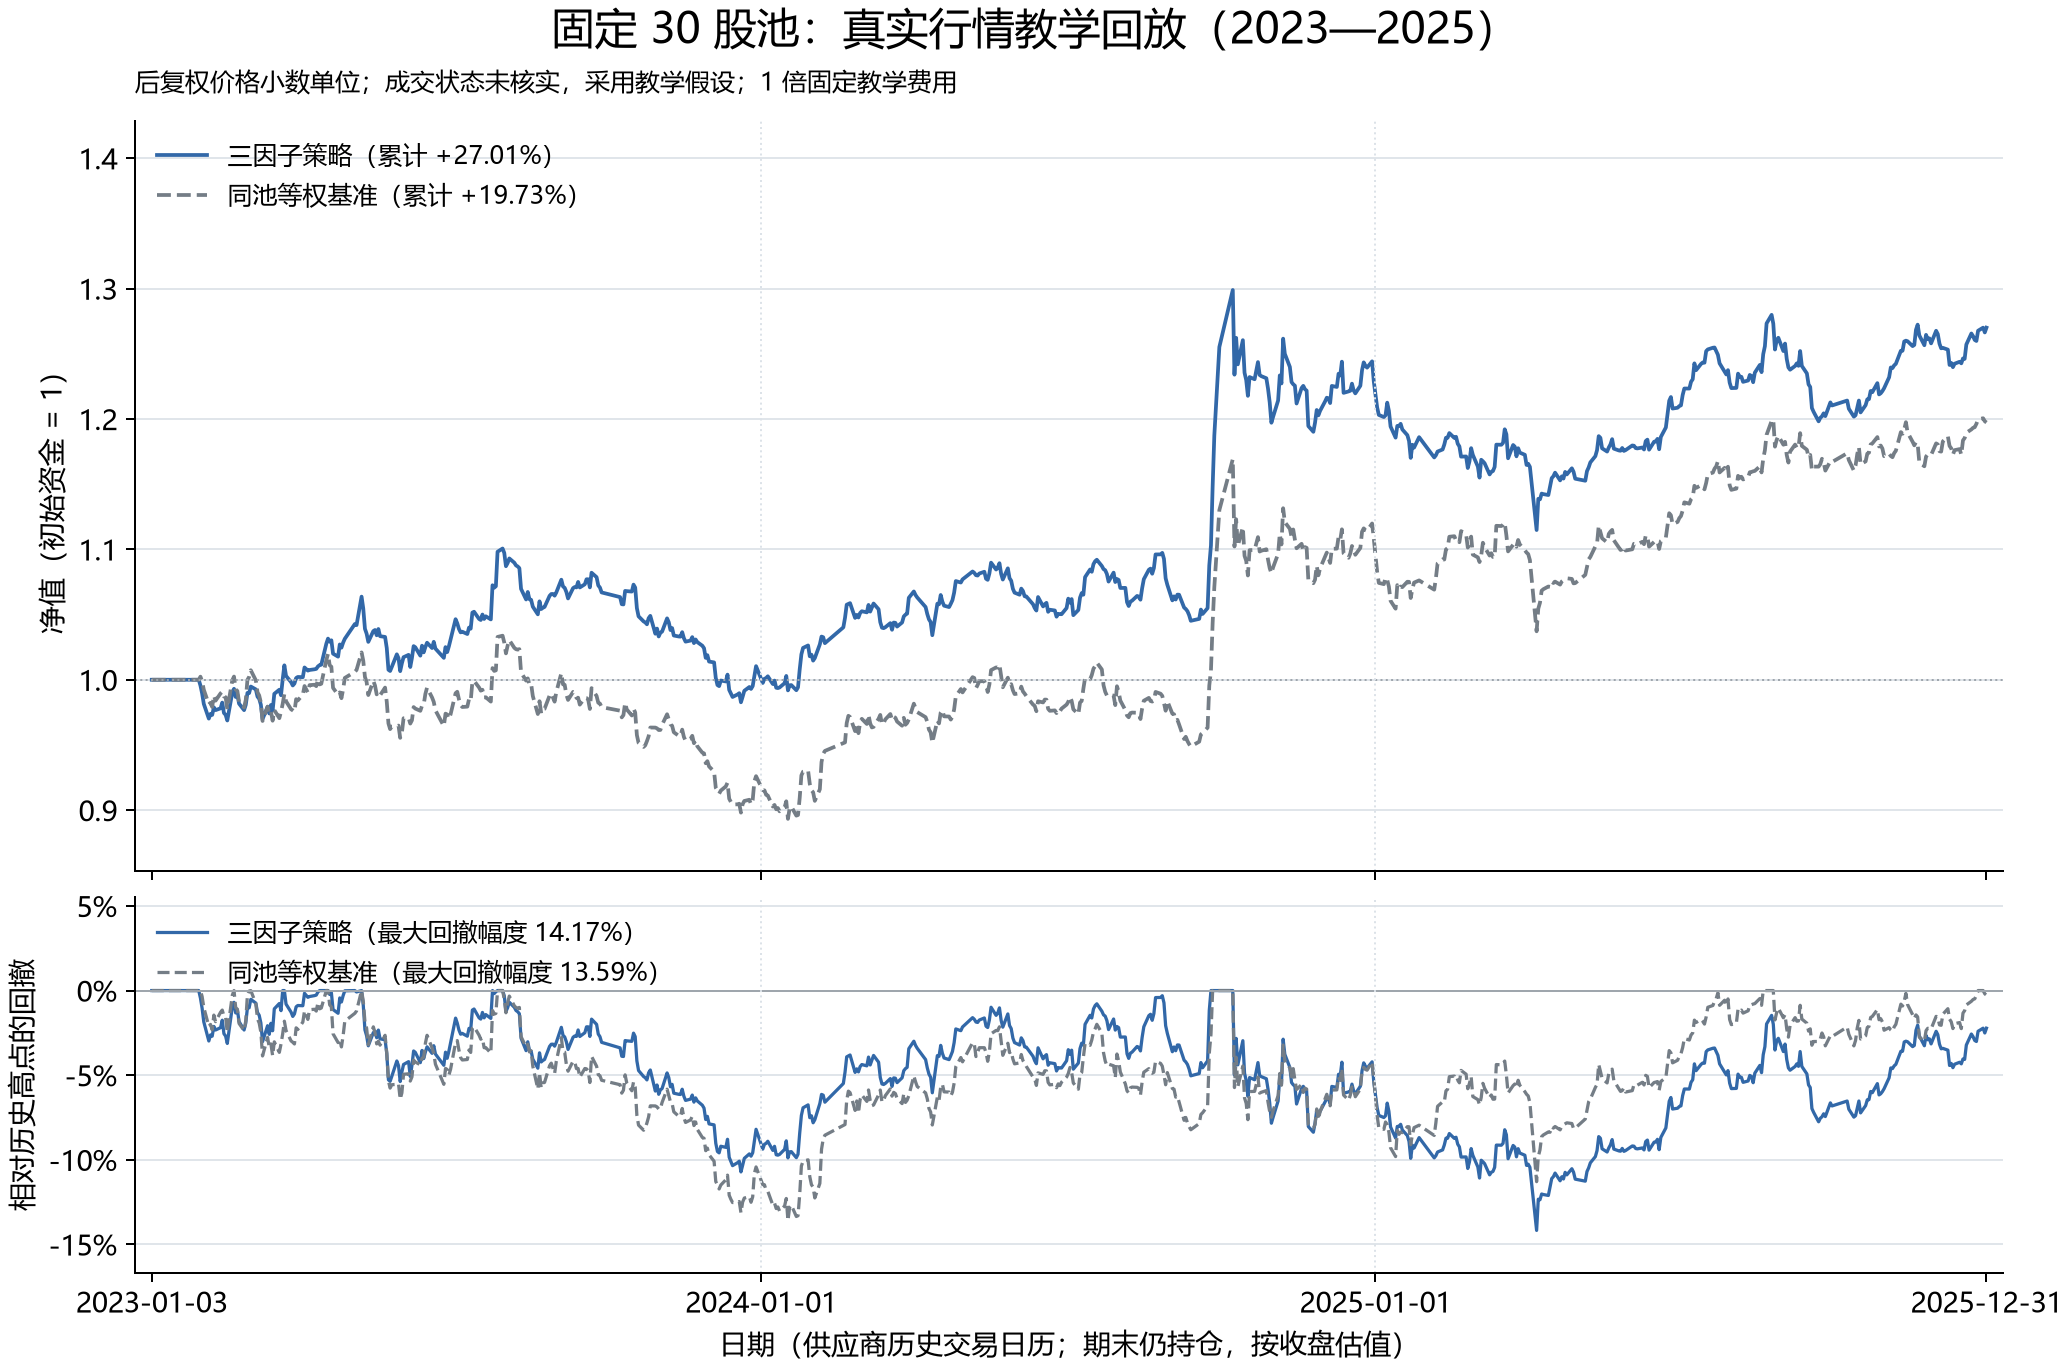

In [10]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT_ROOT / 'runs/lesson18_real_market/real_market_nav_drawdown.png')))

## 运行复核

以上实现已在干净内核中按顺序执行；执行状态记录在仓库的 [Notebook 校验记录](../../publication/notebook_validation.json)。代码中的数据身份、费用和成交假设仍然适用，运行成功只验证对应实现。